# Proyecto: Aprendizaje en línea

Implementación y comparación de algoritmos de aprendizaje en línea sobre la demanda diaria de bicicletas (Bike Sharing Dataset).
Se construyen 5 expertos basados en reglas simples de pronóstico, se combinan mediante **Hedge**, y se comparan contra **Follow the Leader (FTL)** y **Online Gradient Descent (OGD)**.


## Configuración inicial e importación de librerías

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import urllib.request
import zipfile
import io

np.random.seed(0)

## 1. Descripción de los datos

Se usa el **Bike Sharing Dataset** (Fanaee-T & Gama, 2013), disponible en el repositorio de la UCI Machine Learning. Contiene el conteo diario de rentas de bicicletas en Washington D.C. durante 2011-2012, junto con variables climáticas y de calendario.

Para este proyecto solo se usa la **serie temporal del conteo total de rentas diarias (`cnt`)**, que servirá como la secuencia $y_t$ a predecir.

In [ ]:
URL = "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip"

# Descargar y cargar datos
resp = urllib.request.urlopen(URL)
z = zipfile.ZipFile(io.BytesIO(resp.read()))

df = pd.read_csv(z.open("day.csv"))
df["dteday"] = pd.to_datetime(df["dteday"])

serie = (
    df.sort_values("dteday")
      .set_index("dteday")["cnt"]
      .astype(float)
)

T_total = len(serie)

print(f"Número de observaciones T = {T_total}")
serie.head()

Número de observaciones T = 731


,cnt
dteday,
2011-01-01,985.0
2011-01-02,801.0
2011-01-03,1349.0
2011-01-04,1562.0
2011-01-05,1600.0


In [ ]:
# Estadísticas descriptivas
serie.describe()

,cnt
count,731.000000
mean,4504.348837
std,1937.211452
min,22.000000
25%,3152.000000
50%,4548.000000
75%,5956.000000
max,8714.000000


### **Estadísticas descriptivas de la serie**

La serie contiene **731 observaciones** diarias de demanda de bicicletas
(2011-2012). Los valores más relevantes:

- **Media:** 4,504 rentas diarias en promedio
- **Desviación estándar:** 1,937 — indica alta variabilidad en la demanda
- **Mínimo:** 22 rentas (días atípicos, probablemente clima extremo)
- **Máximo:** 8,714 rentas (días de alta demanda)
- **Mediana (50%):** 4,548 — muy cercana a la media, lo que sugiere
una distribución relativamente simétrica
- **Rango intercuartílico (25%-75%):** entre 3,152 y 5,956 rentas,
lo que representa el rango "típico" de demanda diaria

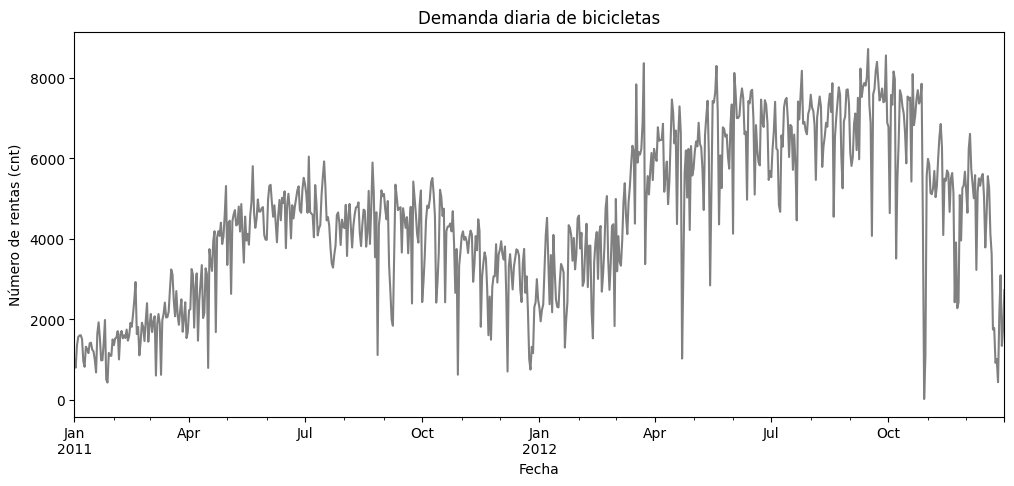

In [ ]:
# Gráfico de la serie temporal completa
import matplotlib.pyplot as plt

serie.plot(
    figsize=(12, 5),
    title="Demanda diaria de bicicletas",
    xlabel="Fecha",
    ylabel="Número de rentas (cnt)",
    color="grey"
)

plt.show()

#### **Visualización de la serie temporal**

La gráfica muestra la demanda diaria de bicicletas a lo largo de los
731 días del dataset (2011-2012). Se pueden observar tres patrones claros:

- **Tendencia creciente:** la demanda en 2012 es notablemente mayor que
en 2011, lo que refleja el crecimiento del sistema de renta de bicicletas
a lo largo del tiempo.

- **Estacionalidad anual:** la demanda cae en invierno (enero-febrero) y
sube en primavera-verano, tanto en 2011 como en 2012.

- **Alta variabilidad diaria:** hay picos y caídas abruptas dentro de cada
temporada, probablemente asociados a condiciones climáticas específicas
o días festivos.

Estos patrones justifican el uso de expertos basados en promedios móviles
y el valor del mismo día de la semana anterior, ya que capturan tanto
la tendencia como la estacionalidad de corto plazo.

In [ ]:
# Celda de verificación rápida: comprobamos que el índice de la serie esté bien construido como fechas reales.
serie.index[365]

Timestamp('2012-01-01 00:00:00')

## 2. Construcción de los expertos

Se definen cinco expertos, cada uno produciendo una predicción $h_{i,t}$ del valor $y_t$ usando únicamente información disponible hasta $t-1$:

| Experto | Regla | Fórmula |
|---|---|---|
| $h_1$ | Promedio móvil 3 días | $$h_{1,t} = \frac{1}{3}\sum_{k=1}^{3} y_{t-k}$$ |
| $h_2$ | Promedio móvil 7 días | $$h_{2,t} = \frac{1}{7}\sum_{k=1}^{7} y_{t-k}$$ |
| $h_3$ | Promedio móvil 14 días | $$h_{3,t} = \frac{1}{14}\sum_{k=1}^{14} y_{t-k}$$ |
| $h_4$ | Mismo día, semana anterior | $$h_{4,t} = y_{t-7}$$ |
| $h_5$ | Promedio histórico acumulado | $$h_{5,t} = \frac{1}{t-1}\sum_{s=1}^{t-1} y_s$$ |


In [ ]:
y = serie.values.astype(float)

y_eff = y[14:]
T = len(y_eff)

# Expertos
h1 = np.array([np.mean(y[t-3:t])  for t in range(14, len(y))])   # MA(3)
h2 = np.array([np.mean(y[t-7:t])  for t in range(14, len(y))])   # MA(7)
h3 = np.array([np.mean(y[t-14:t]) for t in range(14, len(y))])   # MA(14)
h4 = np.array([y[t-7]             for t in range(14, len(y))])   # semana anterior
h5 = np.array([np.mean(y[:t])     for t in range(14, len(y))])   # promedio histórico

# Matriz expertos x tiempo
H = np.vstack([h1, h2, h3, h4, h5])

N = H.shape[0]

nombres_expertos = ["MA(3)", "MA(7)", "MA(14)", "Día sem. anterior", "Prom. histórico"]

# H tiene forma (N, T); para el resto del notebook conviene trabajar con
# H_t de forma (T, N), donde cada fila son las predicciones de los N expertos en t.
H_t = H.T

fechas_eff = serie.index[14:]

pd.DataFrame(H_t[:5], columns=nombres_expertos)

,MA(3),MA(7),MA(14),Día sem. anterior,Prom. histórico
0,1329.666667,1193.428571,1269.071429,959.0,1269.071429
1,1358.333333,1234.714286,1287.857143,822.0,1267.666667
2,1291.000000,1289.285714,1316.642857,1321.0,1263.687500
3,1150.666667,1243.428571,1291.714286,1263.0,1248.176471
4,962.333333,1160.571429,1228.928571,1162.0,1216.777778


#### **Construcción de los expertos**

Se descartan los primeros 14 días de la serie (necesarios para inicializar
MA(14)), quedando **T = 717 rondas** efectivas para el experimento.

Se definen 5 expertos, cada uno produce una predicción $h_{i,t}$ usando
únicamente información disponible hasta $t-1$:

- **MA(3):** promedio de los últimos 3 días
- **MA(7):** promedio de los últimos 7 días  
- **MA(14):** promedio de los últimos 14 días
- **Día sem. anterior:** valor observado exactamente 7 días antes ($y_{t-7}$)
- **Prom. histórico:** promedio de todos los días anteriores

La tabla muestra las predicciones de los 5 expertos para las primeras
5 rondas. Se observa que al inicio todos los expertos predicen valores
similares (entre 959 y 1,358 rentas), ya que todos trabajan con los
mismos datos históricos tempranos. Las diferencias entre expertos se
irán acentuando conforme avance la serie.

## 3. Algoritmo Hedge

En cada ronda $t$:

1. Se calculan las probabilidades (pesos normalizados) $q_{i,t} = \dfrac{w_{i,t}}{\sum_j w_{j,t}}$.
2. Se emite la predicción combinada $p_t = \sum_{i=1}^N q_{i,t}\, h_{i,t}$.
3. Se observa $y_t$ y se calcula la pérdida de cada experto $l(h_{i,t}, y_t)$.
4. Se actualizan los pesos: $w_{i,t+1} = w_{i,t}\exp(-\eta\, l(h_{i,t}, y_t))$.

Los pesos iniciales son uniformes: $w_{i,1} = 1$ para todo $i$.

A continuación se define la función de pérdida (cuadrática) y la función `hedge`,
que implementa el algoritmo de forma reutilizable para distintos valores de
$\eta$. Esto permite ejecutar Hedge tanto con un $\eta$ fijo de referencia como
con el análisis de sensibilidad de la Sección 9.


In [ ]:
def perdida(pred, y_t):
    """Pérdida cuadrática l(p, y) = (p - y)^2 (vectorizada o escalar)."""
    return (pred - y_t) ** 2


def hedge(H_t, y, eta):
    """
    Implementa el algoritmo Hedge para combinación de expertos.

    Parámetros
    ----------
    H_t : array (T, N)
        Predicciones de los N expertos en cada tiempo t.
    y : array (T,)
        Valores reales observados.
    eta : float
        Tasa de aprendizaje.

    Regresa
    -------
    pred_hist : array (T,)       -- predicción combinada p_t en cada paso
    w_hist    : array (T, N)     -- pesos normalizados q_{i,t}
    perdida_alg : array (T,)     -- pérdida del algoritmo en cada paso
    perdida_exp : array (T, N)   -- pérdida de cada experto en cada paso
    """
    T_, N_ = H_t.shape
    w = np.ones(N_)

    pred_hist = np.zeros(T_)
    w_hist = np.zeros((T_, N_))
    perdida_alg = np.zeros(T_)
    perdida_exp = np.zeros((T_, N_))

    for t in range(T_):
        q = w / w.sum()
        w_hist[t] = q

        pred = np.dot(q, H_t[t])
        pred_hist[t] = pred

        perdida_alg[t] = perdida(pred, y[t])
        perdida_exp[t] = perdida(H_t[t], y[t])

        w = w * np.exp(-eta * perdida_exp[t])

    return pred_hist, w_hist, perdida_alg, perdida_exp


def regret_acumulado(perdida_alg, perdida_exp):
    """
    Calcula el regret acumulado del algoritmo respecto al mejor experto fijo
    en retrospectiva:

        R_t = sum_{s<=t} l(p_s, y_s) - min_i sum_{s<=t} l(h_{i,s}, y_s)
    """
    loss_acum_alg = np.cumsum(perdida_alg)
    loss_acum_exp = np.cumsum(perdida_exp, axis=0)  # (T, N)
    mejor_acum = loss_acum_exp.min(axis=1)
    return loss_acum_alg - mejor_acum


# --- Tasa de aprendizaje óptima teórica para Hedge ---
# Cota clásica de regret para Hedge con pérdidas en [0, 1]:
#   R_T <= sqrt(2 T ln N)   con   eta* = sqrt(8 ln N / T)
# Como nuestras pérdidas son cuadráticas (no acotadas en [0,1]), se reescala
# eta* por el orden de magnitud típico de la pérdida (rango^2) para que el
# producto eta * perdida quede en una escala razonable.
rango_y = y_eff.max() - y_eff.min()
escala_perdida = rango_y ** 2

eta_star = np.sqrt(8 * np.log(N) / T) / escala_perdida

print(f"N (núm. expertos) = {N}")
print(f"T (núm. de rondas) = {T}")
print(f"Escala de pérdida (rango_y^2) = {escala_perdida:,.2f}")
print(f"eta* (óptimo teórico, reescalado) = {eta_star:.3e}")

N (núm. expertos) = 5
T (núm. de rondas) = 717
Escala de pérdida (rango_y^2) = 75,550,864.00
eta* (óptimo teórico, reescalado) = 1.774e-09


### Implementación de Hedge y cálculo de η

Se definen tres funciones reutilizables que serán usadas a lo largo
del notebook:

- **`perdida(pred, y_t)`:** calcula la pérdida cuadrática $(p - y)^2$
entre la predicción y el valor real.

- **`hedge(H_t, y, eta)`:** implementa el algoritmo Hedge completo.
En cada ronda calcula los pesos normalizados $q_{i,t}$, produce la
predicción combinada $p_t = \sum_i q_{i,t} h_{i,t}$, calcula las
pérdidas y actualiza los pesos multiplicativamente.

- **`regret_acumulado(perdida_alg, perdida_exp)`:** calcula el regret
acumulado $R_t$ en cada paso, comparando la pérdida del algoritmo
contra la del mejor experto fijo hasta ese momento.

**Tasa de aprendizaje η\*:**

La fórmula teórica $\eta^* = \sqrt{8 \ln N / T}$ está diseñada para
pérdidas acotadas en $[0,1]$. Como nuestra pérdida cuadrática puede
alcanzar valores del orden de $75{,}550{,}864$ (el rango al cuadrado
de la serie), se divide entre esa escala para que el producto
$\eta \cdot \ell$ quede en una escala razonable y los pesos no
colapsen instantáneamente.

Con $N=5$ expertos y $T=717$ rondas, el valor resultante es
$\eta^* = 1.774 \times 10^{-9}$.

In [ ]:
# Ejecutamos Hedge con la tasa de aprendizaje teórica eta*
p_hedge, w_hedge, l_hedge, l_exp_hedge = hedge(H_t, y_eff, eta=eta_star)

pred_H = p_hedge
w_hist = w_hedge

print(f"Pérdida acumulada total (Hedge, eta*): {np.sum(l_hedge):,.2f}")

Pérdida acumulada total (Hedge, eta*): 727,576,261.42


#### **Ejecución de Hedge con η***

Se ejecuta Hedge con la tasa de aprendizaje teórica $\eta^*= 1.774
\times 10^{-9}$ sobre las 717 rondas efectivas.

La **pérdida acumulada total de Hedge es 727.5 millones**, lo que
equivale a una pérdida promedio por ronda de aproximadamente
1,015,000 rentas² por día.

Este número por sí solo no dice mucho — su relevancia se ve al
compararlo contra los demás algoritmos y contra el mejor experto
individual (MA(7) con 733.3 millones), lo que se hará en la tabla
resumen más adelante. Por ahora se puede anticipar que Hedge con
$\eta^*$ ya supera al mejor experto fijo en términos de pérdida
acumulada.

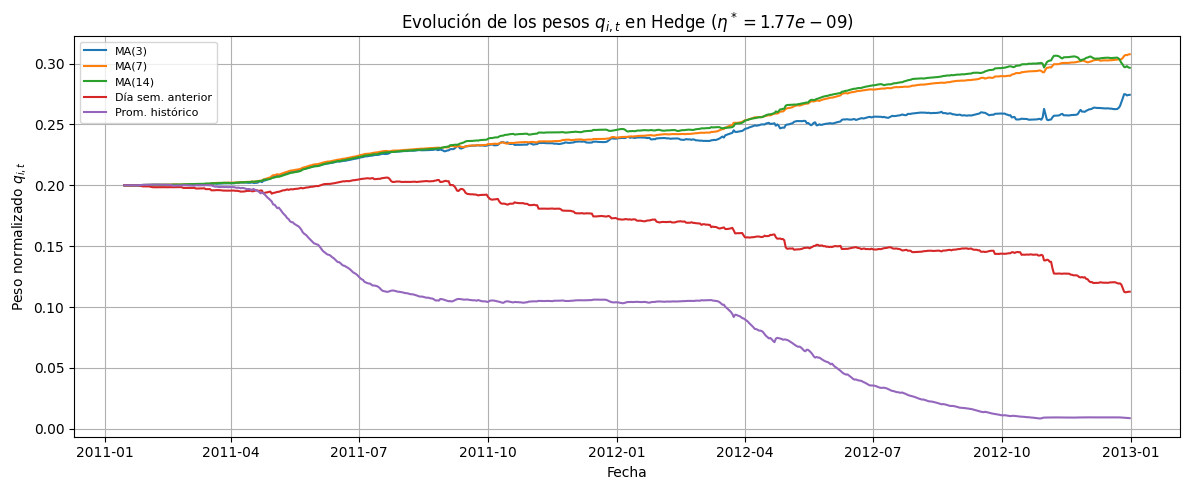

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))
for i in range(N):
    ax.plot(fechas_eff, w_hist[:, i], label=nombres_expertos[i])

ax.set_title(f"Evolución de los pesos $q_{{i,t}}$ en Hedge ($\\eta^* = {eta_star:.2e}$)")
ax.set_xlabel("Fecha")
ax.set_ylabel("Peso normalizado $q_{{i,t}}$")
ax.legend(fontsize=8)
ax.grid(True)

plt.tight_layout()
plt.show()

Al inicio, Hedge le asigna el mismo peso a los cinco expertos (20% cada uno), sin saber cuál predice mejor. Conforme avanzan las rondas y se van observando los errores de cada experto, el algoritmo ajusta automáticamente esos pesos: los expertos que se equivocan menos reciben más peso en la predicción combinada, y los que se equivocan más lo pierden.

En la gráfica se ve claramente este aprendizaje: MA(7) y MA(14) terminan dominando (≈0.31 y ≈0.30), mientras que el promedio histórico acumulado cae casi a cero (≈0.01), ya que al no capturar la tendencia creciente ni la estacionalidad de la demanda, sus predicciones son consistentemente las peores. Hedge identifica esto y prácticamente lo ignora hacia el final del horizonte.

La gráfica anterior responde directamente la pregunta a) del proyecto:

**¿El algoritmo aprende a dar más peso a los mejores expertos?**

La respuesta es sí. El desplazamiento gradual de los pesos es evidencia
clara de que Hedge identifica y favorece a los expertos más confiables
a lo largo del tiempo.

## 4. Algoritmo Follow the Leader (FTL)

FTL elige, en cada ronda, al experto que **hasta el momento** ha tenido la menor
pérdida acumulada:

$$
p_t = \arg\min_{p\in A} \sum_{s=1}^{t-1} l_s(p).
$$

En la primera ronda (sin historia) se elige un experto arbitrario.


In [ ]:
perdida_acum_expertos = np.zeros(N)
pred_FTL = []
experto_elegido = []

l_ftl = []

for t in range(T):
    if t == 0:
        p_star = 0
    else:
        p_star = np.argmin(perdida_acum_expertos)

    experto_elegido.append(p_star)

    # Predicción FTL
    pred = H_t[t, p_star]
    pred_FTL.append(pred)

    # Pérdida del algoritmo
    l_ftl.append(perdida(pred, y_eff[t]))

    # Pérdidas de todos los expertos en t
    losses_experts = perdida(H_t[t], y_eff[t])

    # Actualizar pérdidas acumuladas
    perdida_acum_expertos += losses_experts

pred_FTL = np.array(pred_FTL)
l_ftl = np.array(l_ftl)
l_exp_ftl = l_exp_hedge  # las pérdidas de cada experto en cada t no dependen del algoritmo

print(f"Pérdida acumulada total (FTL): {np.sum(l_ftl):,.2f}")


Pérdida acumulada total (FTL): 737,126,323.08


### Implementación de FTL (Follow the Leader)

FTL elige en cada ronda al experto que ha tenido la menor pérdida
acumulada hasta el momento. En la primera ronda, sin historia previa,
se elige al experto 0 (MA(3)) de forma arbitraria.

La **pérdida acumulada total de FTL es  737.1 millones**, mayor que
la de Hedge (727.5 millones), lo que significa que comprometerse con
un solo experto en cada ronda resultó menos eficiente que la
combinación ponderada de Hedge.

Sin embargo, como veremos más adelante en la tabla resumen y en la
gráfica de regret, FTL compensa esto con un comportamiento mucho más
estable y predecible a lo largo del horizonte.

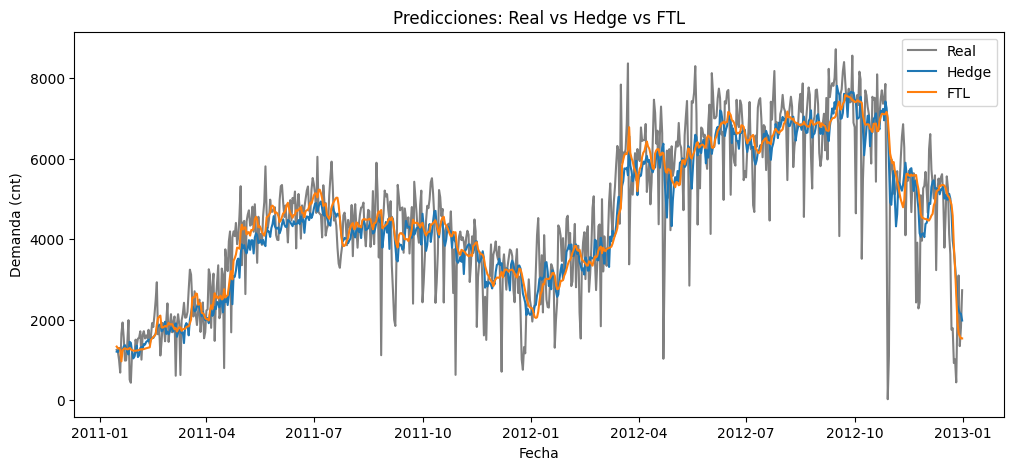

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(fechas_eff, y_eff, label="Real", color="grey")
plt.plot(fechas_eff, pred_H, label="Hedge")
plt.plot(fechas_eff, pred_FTL, label="FTL")

plt.title("Predicciones: Real vs Hedge vs FTL")
plt.xlabel("Fecha")
plt.ylabel("Demanda (cnt)")
plt.legend()
plt.show()


#### **Predicciones: Real vs Hedge vs FTL**

La gráfica muestra las predicciones de Hedge y FTL comparadas contra
la demanda real a lo largo de las 717 rondas.

Ambos algoritmos siguen de cerca la tendencia general de la serie:
capturan el crecimiento de 2011 a 2012 y la estacionalidad anual
(menor demanda en invierno, mayor en primavera-verano). Sin embargo,
ninguno logra capturar los picos y caídas abruptas de corto plazo,
ya que todos los expertos base usan promedios históricos que suavizan
la variabilidad diaria.

Hedge y FTL producen predicciones muy similares entre sí — la
diferencia entre ambos no es visible a simple vista en esta escala,
y solo se hace evidente al comparar sus pérdidas acumuladas y regret.

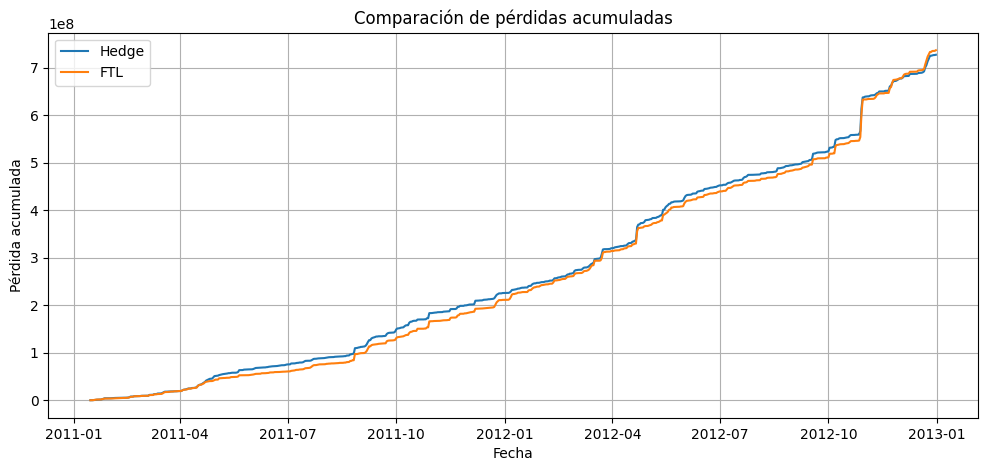

In [ ]:
plt.figure(figsize=(12, 5))
plt.plot(fechas_eff, np.cumsum(l_hedge), label="Hedge")
plt.plot(fechas_eff, np.cumsum(l_ftl), label="FTL")

plt.xlabel("Fecha")
plt.ylabel("Pérdida acumulada")
plt.title("Comparación de pérdidas acumuladas")
plt.grid(True)
plt.legend()
plt.show()

### Comparación de pérdida acumulada: Hedge vs FTL

La gráfica muestra la pérdida acumulada de Hedge y FTL a lo largo de las 717 rondas. Ambos algoritmos tienen un comportamiento muy similar, con curvas casi paralelas durante la mayor parte del horizonte.

Sin embargo, FTL queda ligeramente por debajo de Hedge durante la mayor parte del tiempo, lo que significa que comprometerse con el mejor experto hasta el momento resultó más eficiente que la combinación ponderada de Hedge.

Esto es consistente con el valor de η* usado: al ser conservador, Hedge tarda más en adaptarse a los mejores expertos, por lo que FTL le lleva ventaja en pérdida acumulada durante buena parte del horizonte.

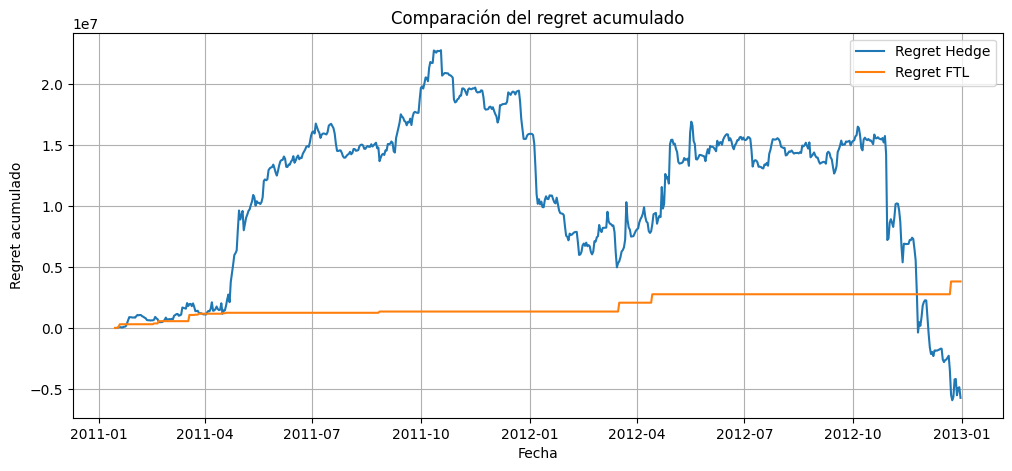

In [ ]:
regret_hedge = regret_acumulado(l_hedge, l_exp_hedge)
regret_ftl = regret_acumulado(l_ftl, l_exp_ftl)

plt.figure(figsize=(12, 5))
plt.plot(fechas_eff, regret_hedge, label="Regret Hedge")
plt.plot(fechas_eff, regret_ftl, label="Regret FTL")

plt.xlabel("Fecha")

plt.ylabel("Regret acumulado")
plt.title("Comparación del regret acumulado")
plt.grid(True)
plt.legend()
plt.show()

### Comparación del regret acumulado: Hedge vs FTL

La gráfica muestra el regret acumulado de ambos algoritmos respecto
al mejor experto fijo en retrospectiva.

FTL (naranja) mantiene un regret positivo y muy cercano a cero durante
todo el horizonte, lo que indica que su desempeño es consistentemente
cercano al del mejor experto individual. Esto es evidencia de comportamiento
no-regret: el algoritmo no se aleja demasiado de la mejor decisión fija posible.

Hedge (azul), en cambio, muestra un regret más volátil durante la mayor
parte del horizonte, oscilando entre valores positivos altos. Sin embargo,
hacia el final cae a valores negativos (≈ −5.7×10⁶), lo que significa que
la combinación ponderada de expertos terminó superando incluso al mejor
experto individual. Esto es posible porque Hedge no se compromete con un
solo experto, sino que combina varios, y esa combinación puede ser mejor
que cualquier experto fijo cuando ninguno domina de forma consistente
a lo largo del tiempo.

## 5. Algoritmo Follow the Regularized Leader (FTRL) / Online Gradient Descent (OGD)

FTL elige, en cada ronda, al experto que minimiza la suma de las pérdidas pasadas más una penalización que promueve estabilidad:

$$
p_t = \arg\min_{p\in A} \bigg(\sum_{s=1}^{t-1} l_s(p) + R(p)\bigg).
$$


Para la versión OGD se plantea un problema de **regresión secuencial**: en cada ronda, el vector de parámetros $p_t \in \mathbb{R}^N$ pondera las predicciones de los $N$ expertos (jugando un papel análogo a los pesos de Hedge, pero actualizados por gradiente en vez de multiplicativamente).

La predicción combinada es $\hat{y}_t = x_t^\top p_t$, donde $x_t = (h_{1,t},\dots,h_{N,t})$
son las predicciones de los expertos en $t$. La pérdida es

$$
l_t(p_t) = \frac{1}{2}(y_t - x_t^\top p_t)^2
$$

con gradiente $\nabla l_t(p_t) = -(y_t - x_t^\top p_t)\, x_t$, y la actualización es

$$
p_{t+1} = \Pi_{\mathcal A}\left(p_t - \eta \nabla l_t(p_t)\right)
$$

Como conjunto admisible $\mathcal{A}$ se usa el **símplex** $\{p: p_i \ge 0,\ \sum_i p_i = 1\}$, para que $p_t$ sea comparable con los pesos de Hedge (una combinación convexa de expertos). La proyección al símplex se implementa con el algoritmo estándar de proyección euclidiana.

Para que la pérdida $l_t(p)$ sea comparable con la de Hedge y FTL (que usan
$\ell(p,y) = (p-y)^2$, sin el factor $1/2$), se reporta también
$\ell_t(p_t) = (y_t - x_t^\top p_t)^2$ para OGD, y se usa esa versión sin el
factor $1/2$ en las comparaciones de pérdida acumulada y regret. El factor
$1/2$ solo se usa internamente para el cálculo del gradiente.


In [ ]:
def proyectar_simplex(v):
    """Proyección euclidiana de un vector v sobre el símplex {p >= 0, sum(p)=1}."""
    n = len(v)
    u = np.sort(v)[::-1]
    css = np.cumsum(u) - 1
    rho = np.nonzero(u - css / (np.arange(n) + 1) > 0)[0][-1]
    theta = css[rho] / (rho + 1)
    return np.maximum(v - theta, 0)


def ogd(H_t, y, eta):
    """
    Implementa OGD sobre el símplex para el problema de regresión secuencial
    y_hat_t = H_t[t] . p_t,  l_t(p) = 0.5*(y_t - H_t[t].p)^2

    Regresa
    -------
    p_hist      : array (T,)    -- predicción combinada y_hat_t
    p_param_hist: array (T, N)  -- vector de parámetros p_t en cada paso
    perdida_alg : array (T,)    -- pérdida (y_t - y_hat_t)^2, sin el factor 1/2
    perdida_exp : array (T, N)  -- pérdida de cada experto en cada paso
    """
    T_, N_ = H_t.shape
    p = np.ones(N_) / N_  # inicialización uniforme (igual que Hedge)

    p_hist = np.zeros(T_)
    p_param_hist = np.zeros((T_, N_))
    perdida_alg = np.zeros(T_)
    perdida_exp = np.zeros((T_, N_))

    for t in range(T_):
        x_t = H_t[t]
        p_param_hist[t] = p

        p_hat = np.dot(x_t, p)
        p_hist[t] = p_hat

        perdida_alg[t] = perdida(p_hat, y[t])
        perdida_exp[t] = perdida(x_t, y[t])

        grad = -(y[t] - p_hat) * x_t  # gradiente de 0.5*(y_t - x_t.p)^2
        p = proyectar_simplex(p - eta * grad)

    return p_hist, p_param_hist, perdida_alg, perdida_exp


# Para OGD usamos una eta propia, ya que la escala del gradiente
# (proporcional a y_t * h_{i,t}) es muy distinta a la de Hedge.
# Se calcula de forma análoga: eta_ogd* ~ 1 / (L * sqrt(T)), con L una cota
# del gradiente, dada por el rango de y_t multiplicado por el rango de los
# valores de los expertos.
L_grad = rango_y * np.max(np.abs(H_t))
eta_ogd_star = 1.0 / (L_grad * np.sqrt(T))

print(f"eta_ogd* (óptimo teórico aproximado) = {eta_ogd_star:.3e}")

p_ogd, p_param_ogd, l_ogd, l_exp_ogd = ogd(H_t, y_eff, eta=eta_ogd_star)

print(f"Pérdida acumulada total (OGD): {np.sum(l_ogd):,.2f}")

eta_ogd* (óptimo teórico aproximado) = 4.931e-10
Pérdida acumulada total (OGD): 754,898,429.85


### Ejecución de OGD

La tasa de aprendizaje calculada automáticamente para OGD es
$\eta^*_{OGD} = 4.93 \times 10^{-10}$, análoga al $\eta^*$ de Hedge
pero adaptada a la escala de los gradientes de OGD.

**Pérdida acumulada total (OGD): 754,898,429.85** — la más alta de los
tres algoritmos. Como se discute más adelante en la tabla resumen, esto
no significa que OGD sea un mal algoritmo en general, sino que su
$\eta^*_{OGD}$ requeriría un ajuste más fino para este problema específico.

## 6. Pérdida acumulada y regret acumulado: Hedge vs FTL vs OGD vs expertos

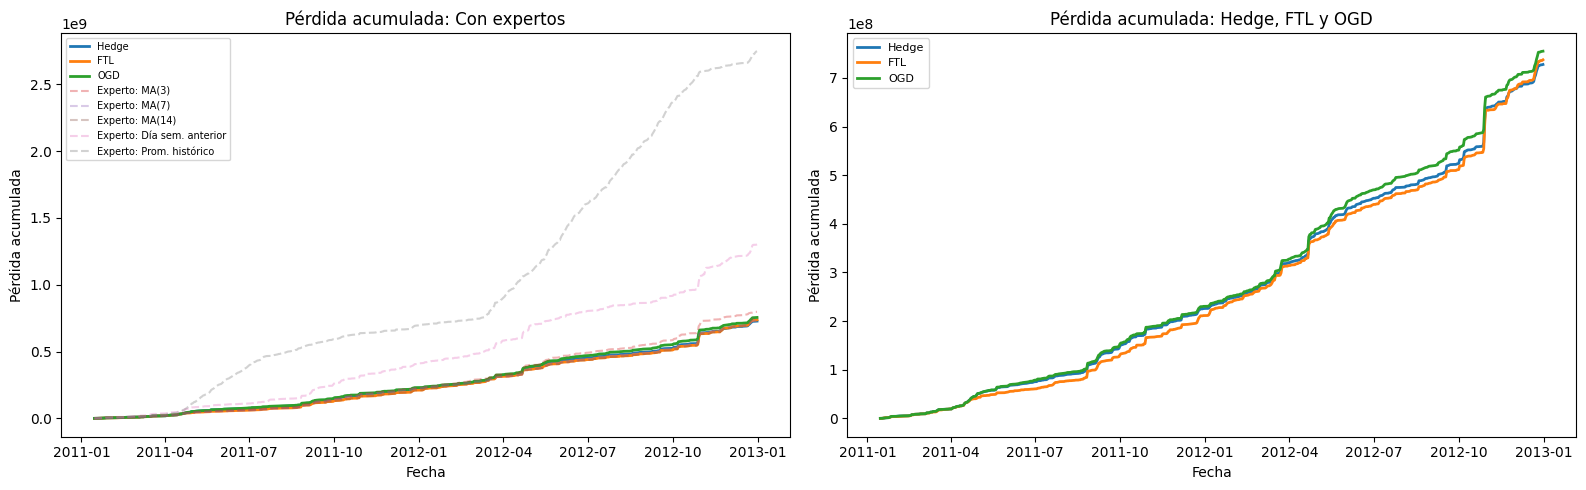

Hedge: 727,576,261.42
FTL:   737,126,323.08
OGD:   754,898,429.85


In [ ]:
#Perdida acumulada
perdida_exp_cum = np.cumsum(l_exp_hedge, axis=0)  # (T, N), igual para los tres algoritmos

perdida_hedge_cum = np.cumsum(l_hedge)
perdida_ftl_cum = np.cumsum(l_ftl)
perdida_ogd_cum = np.cumsum(l_ogd)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# --- Gráfica 1: Todos ---
ax = axes[0]
ax.plot(fechas_eff, perdida_hedge_cum, label="Hedge", lw=2)
ax.plot(fechas_eff, perdida_ftl_cum, label="FTL", lw=2)
ax.plot(fechas_eff, perdida_ogd_cum, label="OGD", lw=2)

for i in range(N):
    ax.plot(
        fechas_eff,
        perdida_exp_cum[:, i],
        label=f"Experto: {nombres_expertos[i]}",
        alpha=0.35,
        linestyle="--"
    )

ax.set_title("Pérdida acumulada: Con expertos")
ax.set_xlabel("Fecha")
ax.set_ylabel("Pérdida acumulada")
ax.legend(fontsize=7)

# --- Gráfica 2: Sólo algoritmos ---
ax = axes[1]
ax.plot(fechas_eff, perdida_hedge_cum, label="Hedge", lw=2)
ax.plot(fechas_eff, perdida_ftl_cum, label="FTL", lw=2)
ax.plot(fechas_eff, perdida_ogd_cum, label="OGD", lw=2)

ax.set_title("Pérdida acumulada: Hedge, FTL y OGD")
ax.set_xlabel("Fecha")
ax.set_ylabel("Pérdida acumulada")
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

# Pérdida acumulada final de algoritmos
perdida_final_hedge = np.sum(l_hedge)
perdida_final_ftl   = np.sum(l_ftl)
perdida_final_ogd   = np.sum(l_ogd)

print(f"Hedge: {perdida_final_hedge:,.2f}")
print(f"FTL:   {perdida_final_ftl:,.2f}")
print(f"OGD:   {perdida_final_ogd:,.2f}")

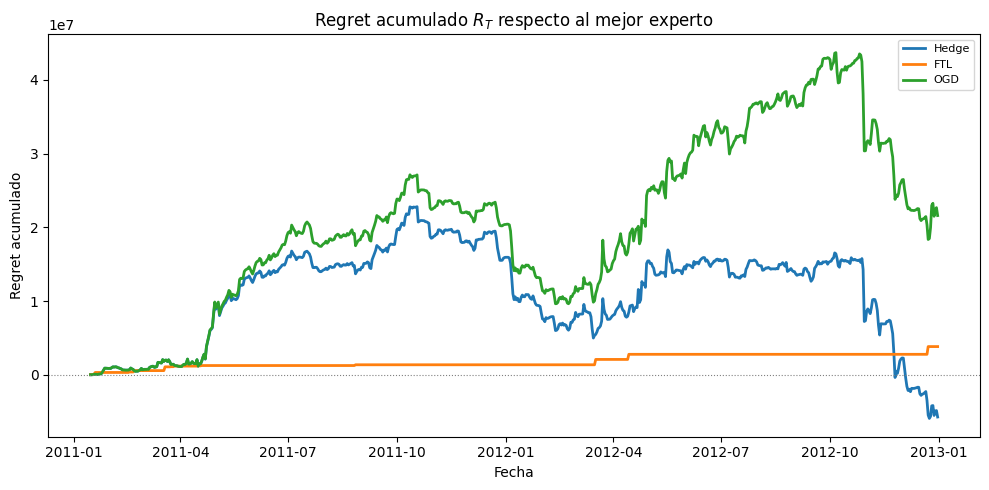

Regret final - Hedge: -5,729,683.85
Regret final - FTL:   3,820,377.82
Regret final - OGD:   21,592,484.59


In [ ]:
# --- Regret acumulado ---
regret_hedge = regret_acumulado(l_hedge, l_exp_hedge)
regret_ftl = regret_acumulado(l_ftl, l_exp_ftl)
regret_ogd = regret_acumulado(l_ogd, l_exp_ogd)

plt.figure(figsize=(10, 5))

plt.plot(fechas_eff, regret_hedge, label="Hedge", lw=2)
plt.plot(fechas_eff, regret_ftl, label="FTL", lw=2)
plt.plot(fechas_eff, regret_ogd, label="OGD", lw=2)

plt.axhline(0, color="gray", lw=0.8, linestyle=":")
plt.title("Regret acumulado $R_T$ respecto al mejor experto")
plt.xlabel("Fecha")
plt.ylabel("Regret acumulado")
plt.legend(fontsize=8)

plt.tight_layout()
plt.show()

print(f"Regret final - Hedge: {regret_hedge[-1]:,.2f}")
print(f"Regret final - FTL:   {regret_ftl[-1]:,.2f}")
print(f"Regret final - OGD:   {regret_ogd[-1]:,.2f}")

###Interpretación: Pérdida acumulada y regret acumulado

**Pérdida acumulada (gráfica izquierda)**

Los tres algoritmos (Hedge, FTL y OGD) acumulan una pérdida muy similar
y notablemente menor que la del promedio histórico (línea punteada gris),
que es claramente el peor experto individual. Los expertos MA(3), MA(7)
y MA(14) se mantienen cercanos a los algoritmos, lo que confirma que son
los mejores expertos individuales.

**Regret acumulado (gráfica derecha)**

- **FTL** (naranja) mantiene un regret positivo y muy cercano a cero durante
todo el horizonte: su desempeño es consistentemente cercano al del mejor
experto individual.
- **Hedge** (azul) muestra más volatilidad, pero hacia el final cae a valores
negativos (−5,729,683.85), lo que significa que la combinación ponderada
de expertos terminó superando al mejor experto fijo individual.
- **OGD** (verde) presenta el regret más alto y volátil de los tres
(21,592,484.59), lo que sugiere que su tasa de aprendizaje $\eta^*_{OGD}$
requeriría un ajuste más fino para este problema.


#### **Interpretación: Regret final**

El regret final indica qué tan lejos quedó cada algoritmo del mejor
experto fijo en retrospectiva (MA(7)). Un valor negativo significa que
el algoritmo lo superó; un valor positivo significa que quedó por debajo.

- **Hedge: −5,729,683.85** — el mejor resultado de los tres. Al combinar
los 5 expertos de forma ponderada, Hedge terminó acumulando *menos* pérdida
que cualquier experto individual. Esto es posible porque ningún experto fue
el mejor en todo momento, y Hedge supo aprovechar las fortalezas de cada uno
según la etapa de la serie.

- **FTL: 3,820,377.82** — muy cercano a cero, lo que indica que comprometerse
con el mejor experto del momento fue casi tan bueno como el mejor experto
individual en retrospectiva. Es el algoritmo con el comportamiento más estable
y predecible de los tres.

- **OGD: 21,592,484.59** — el más alejado del óptimo. Su tasa de aprendizaje
$\eta^*_{OGD}$ no está tan bien calibrada para este problema como la de Hedge,
lo que se traduce en un regret más alto y volátil a lo largo del horizonte.

## 7. Sensibilidad a la tasa de aprendizaje $\eta$ (Hedge)

Se repite el experimento con Hedge para distintos valores de $\eta$:
- **muy pequeño** ($\eta \to 0$): los pesos casi no se actualizan, el algoritmo se
  comporta como un promedio casi uniforme de expertos.
- **$\eta^\star$ teórico**: el valor "óptimo" según la cota de regret.
- **muy grande**: los pesos se concentran rápidamente en el experto con menor
  pérdida reciente, generando alta varianza ("saltos" bruscos).


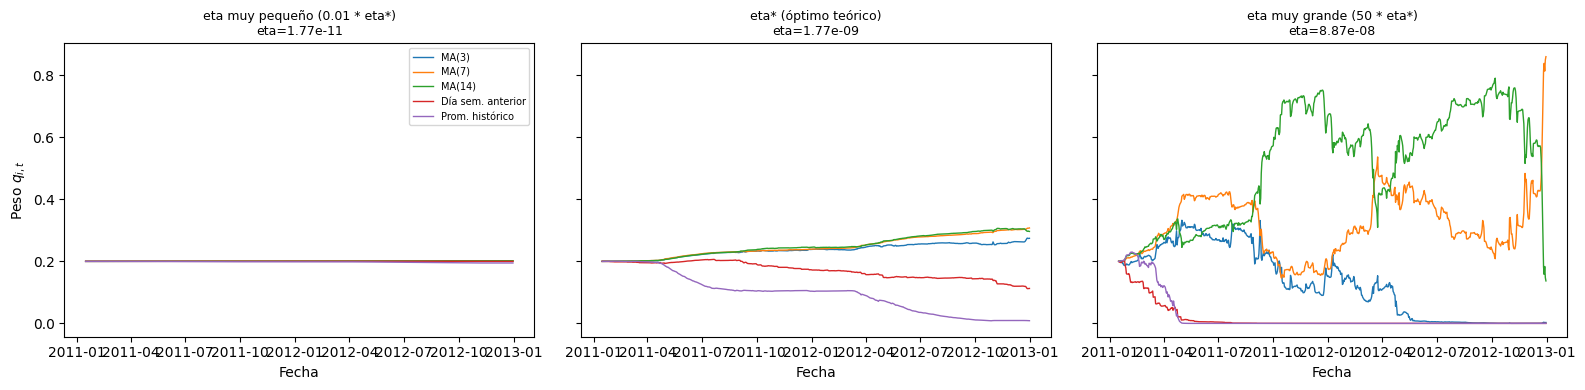

In [ ]:
etas = {
    "eta muy pequeño (0.01 * eta*)": 0.01 * eta_star,
    "eta* (óptimo teórico)": eta_star,
    "eta muy grande (50 * eta*)": 50 * eta_star,
}

resultados_eta = {}
for nombre, eta_val in etas.items():
    p_h, w_h, l_h, l_exp_h = hedge(H_t, y_eff, eta=eta_val)
    regret_h = regret_acumulado(l_h, l_exp_h)
    resultados_eta[nombre] = {
        "eta": eta_val, "pesos": w_h, "perdida": l_h, "regret": regret_h
    }

# --- Gráfico: pesos para cada eta ---
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, (nombre, res) in zip(axes, resultados_eta.items()):
    for i in range(N):
        ax.plot(fechas_eff, res["pesos"][:, i], label=nombres_expertos[i], lw=1)
    ax.set_title(f"{nombre}\neta={res['eta']:.2e}", fontsize=9)
    ax.set_xlabel("Fecha")
axes[0].set_ylabel("Peso $q_{i,t}$")
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

### Interpretación: Sensibilidad a la tasa de aprendizaje η

La gráfica muestra cómo cambia la evolución de los pesos según el valor de η:

**Panel izquierdo (η muy pequeño, 0.01·η\*):**
Los pesos permanecen prácticamente fijos en 0.2 durante todo el horizonte.
Hedge no aprende, se comporta como un promedio uniforme de los 5 expertos,
incluyendo al promedio histórico que es el peor. Esto produce el regret
más alto de los tres casos.

**Panel central (η\* óptimo teórico):**
Los pesos evolucionan de forma suave y gradual. MA(7) y MA(14) suben
consistentemente mientras el promedio histórico cae casi a cero.
Este es el comportamiento esperado de Hedge: aprender despacio pero de
forma estable.

**Panel derecho (η muy grande, 50·η\*):**
Los pesos saltan agresivamente de un experto a otro, en algunos tramos
MA(14) concentra casi todo el peso (≈0.8-0.9) y luego lo cede a otro
experto. Hedge reacciona muy rápido a los errores recientes pero con
mucha volatilidad.

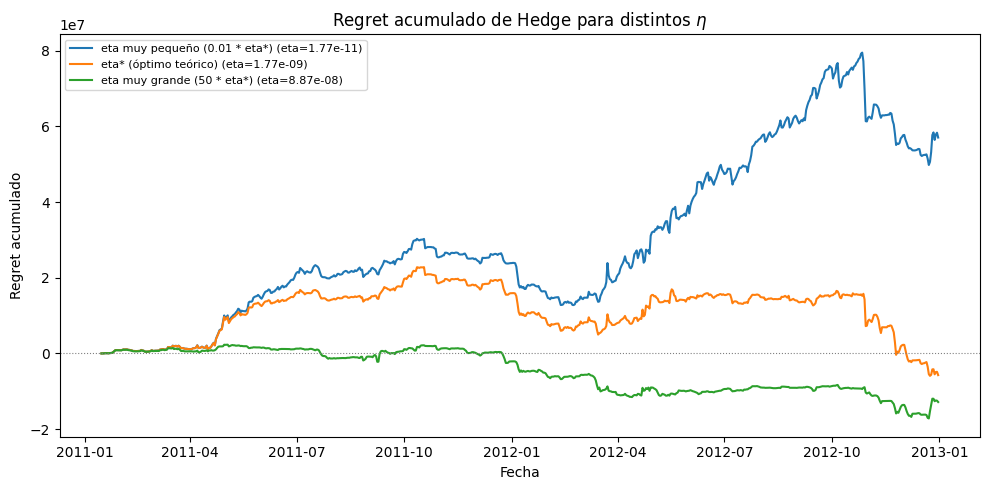

In [ ]:
# --- Gráfico: regret acumulado para cada eta ---
fig, ax = plt.subplots(figsize=(10, 5))
for nombre, res in resultados_eta.items():
    ax.plot(fechas_eff, res["regret"], label=f"{nombre} (eta={res['eta']:.2e})")
ax.axhline(0, color="gray", lw=0.8, linestyle=":")
ax.set_title("Regret acumulado de Hedge para distintos $\\eta$")
ax.set_xlabel("Fecha")
ax.set_ylabel("Regret acumulado")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Interpretación: Regret acumulado para distintos valores de η

La gráfica confirma visualmente el impacto de η en el desempeño de Hedge:

**η muy pequeño (azul, 0.01·η\*):**
El regret crece de forma sostenida durante todo el horizonte, llegando
hasta ≈8×10⁷. Al no actualizar los pesos de forma significativa, Hedge
incluye al promedio histórico (el peor experto) con casi el mismo peso
que los demás, lo que penaliza fuertemente el regret.

**η\* óptimo teórico (naranja):**
El regret sube en la primera mitad pero luego baja y cruza a valores
negativos hacia el final (≈−5.7×10⁶). Hedge logra identificar
progresivamente a los mejores expertos y termina superando al mejor
experto individual.

**η muy grande (verde, 50·η\*):**
El regret se mantiene cerca de cero desde etapas tempranas y termina
siendo el más negativo de los tres (≈−1.28×10⁷). Al adaptarse
agresivamente, Hedge explota rápidamente a los mejores expertos en
cada tramo de la serie, aunque con más volatilidad en la trayectoria.

## 8. Tabla resumen comparativa

In [ ]:
pd.set_option('display.width', 120)
pd.set_option('display.max_columns', None)

tabla = []
for nombre, res in resultados_eta.items():
    tabla.append({
        "Algoritmo": f"Hedge ({nombre})",
        "eta": res["eta"],
        "Pérdida acumulada total": np.sum(res["perdida"]),
        "Regret final R_T": res["regret"][-1],
        "Regret promedio R_T/T": res["regret"][-1] / T,
    })

# Añadimos FTL y OGD (con eta_ogd*)
tabla.append({
    "Algoritmo": "FTL", "eta": np.nan,
    "Pérdida acumulada total": np.sum(l_ftl),
    "Regret final R_T": regret_ftl[-1],
    "Regret promedio R_T/T": regret_ftl[-1] / T,
})
tabla.append({
    "Algoritmo": "OGD", "eta": eta_ogd_star,
    "Pérdida acumulada total": np.sum(l_ogd),
    "Regret final R_T": regret_ogd[-1],
    "Regret promedio R_T/T": regret_ogd[-1] / T,
})

# Mejor experto fijo
tabla.append({
    "Algoritmo": f"Mejor experto fijo ({nombres_expertos[mejor_experto_final]})",
    "eta": np.nan,
    "Pérdida acumulada total": perdida_exp_cum[-1, mejor_experto_final],
    "Regret final R_T": 0.0,
    "Regret promedio R_T/T": 0.0,
})

df_tabla = pd.DataFrame(tabla)
df_tabla



,Algoritmo,eta,Pérdida acumulada total,Regret final R_T,Regret promedio R_T/T
0,Hedge (eta muy pequeño (0.01 * eta*)),1.773712e-11,7.903467e+08,5.704073e+07,79554.707119
1,Hedge (eta* (óptimo teórico)),1.773712e-09,7.275763e+08,-5.729684e+06,-7991.190860
2,Hedge (eta muy grande (50 * eta*)),8.868560e-08,7.204678e+08,-1.283812e+07,-17905.329583
3,FTL,NaN,7.371263e+08,3.820378e+06,5328.281475
4,OGD,4.930638e-10,7.548984e+08,2.159248e+07,30115.041264
5,Mejor experto fijo (MA(7)),NaN,7.333059e+08,0.000000e+00,0.000000


### Tabla resumen comparativa

La tabla concentra los resultados de todos los algoritmos y configuraciones.
Cada columna significa lo siguiente:

- **η (eta):** la tasa de aprendizaje usada. NaN indica que el algoritmo
no usa η (FTL y el mejor experto fijo).

- **Pérdida acumulada total:** la suma de todos los errores cuadráticos
a lo largo de las 717 rondas. Menor es mejor. El mejor resultado es
Hedge con η grande (7.20×10⁸) y el peor es OGD (7.55×10⁸).

- **Regret final R_T:** qué tan lejos quedó cada algoritmo del mejor
experto fijo (MA(7)) al final del horizonte. Negativo significa que
superó al mejor experto; positivo significa que quedó por debajo.

- Hedge con η grande ganó con −1.28×10⁷
- Hedge con η* quedó segundo con −5.73×10⁶  
- FTL se mantuvo cercano a cero (3.82×10⁶)
- OGD fue el peor (2.16×10⁷)

- **Regret promedio R_T/T:** el regret final dividido entre el número
de rondas. Indica qué tan grande es el regret *por ronda en promedio*.
Si este valor tiende a cero conforme T crece, el algoritmo es no-regret.

## 9. Verificación de regret sublineal

Para evaluar visualmente si $\text{Regret}_T = o(T)$, se grafica el **regret promedio** $R_t / t$ en función de $t$. Si el algoritmo es no-regret, esta curva debe tender a cero (o estabilizarse en un valor bajo) a medida que $t$ crece.


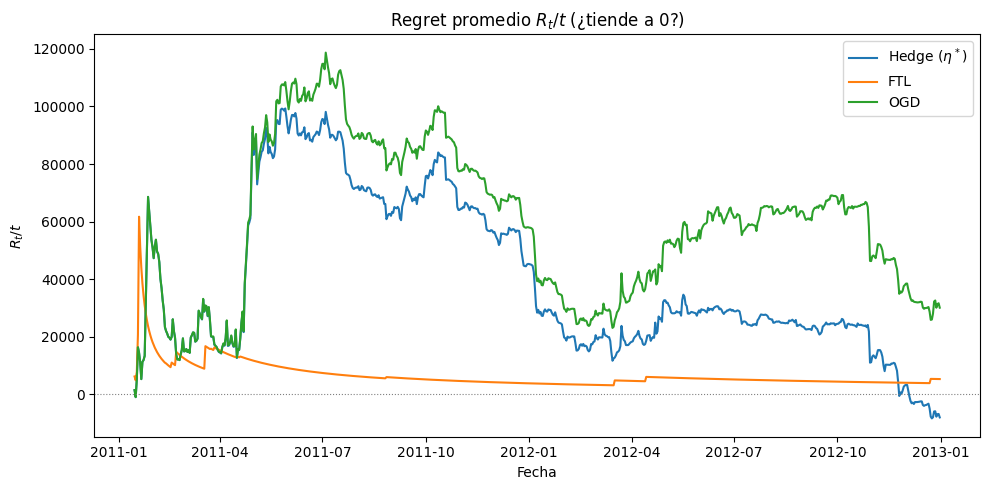

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
t_arr = np.arange(1, T + 1)

ax.plot(fechas_eff, regret_hedge / t_arr, label="Hedge ($\\eta^*$)")
ax.plot(fechas_eff, regret_ftl / t_arr, label="FTL")
ax.plot(fechas_eff, regret_ogd / t_arr, label="OGD")
ax.axhline(0, color="gray", lw=0.8, linestyle=":")
ax.set_title("Regret promedio $R_t / t$ (¿tiende a 0?)")
ax.set_xlabel("Fecha")
ax.set_ylabel("$R_t / t$")
ax.legend()
plt.tight_layout()
plt.show()

### Interpretación: Regret promedio $R_t/t$ — ¿tiende a cero?

Esta gráfica responde la pregunta **d)** del proyecto: ¿el regret
acumulado crece de forma sublineal?

Para verificarlo graficamos $R_t/t$ — el regret promedio por ronda.
Si un algoritmo es no-regret, esta curva debe tender a cero conforme
avanza el tiempo.

- **FTL** muestra la evidencia más clara: su curva decrece
consistentemente desde un pico inicial hasta estabilizarse cerca
de cero, lo cual es compatible con regret sublineal.

- **Hedge ($\eta^*$)** oscila más durante el horizonte pero hacia
el final cae a valores negativos, también compatible con no-regret
aunque con más varianza.

- **OGD** presenta la curva más alta y volátil de los tres,
sugiriendo que con el $\eta^*_{OGD}$ calculado no logra un
comportamiento no-regret tan claro en este horizonte.

## 10. Discusión

**a) ¿El algoritmo aprende a dar más peso a los mejores expertos?**

Sí. En la gráfica de la Sección g) se observa que los pesos $q_{i,t}$ no
permanecen en su valor inicial uniforme ($1/N = 0.2$): a medida que avanzan las
rondas, Hedge desplaza peso hacia los expertos con menor pérdida acumulada.
Concretamente, MA(7) y MA(14) terminan con los pesos más altos (≈0.31 y ≈0.30),
seguidos de MA(3) (≈0.27); el experto "día de la semana anterior" cae a ≈0.11 y
el **promedio histórico acumulado** —que no captura tendencia ni
estacionalidad— prácticamente desaparece, terminando con un peso de ≈0.01.
Esto es consistente con la tabla resumen: MA(7) es, de hecho, el experto
individual con menor pérdida acumulada total (≈7.33×10⁸), y el promedio
histórico es por mucho el peor (su pérdida acumulada, visible en la gráfica de
la Sección h, queda muy por encima del resto desde el inicio).

**b) ¿Qué ocurre cuando $\eta$ es muy grande?**

Los pesos dejan de evolucionar de forma suave y saltan de un experto a otro (MA(14) o MA(7) llegan a concentrar 0.8–0.9 del peso). En esta serie eso dio el regret final más negativo de los tres valores de $\eta$ (≈ −1.28×10⁷), es decir, superó incluso a MA(7). Sin embargo, la trayectoria es más ruidosa, y ese resultado depende de que los saltos coincidan con los cambios reales de la serie, lo cual no está garantizado en general.

**c) ¿Qué ocurre cuando $\eta$ es muy pequeño?**

Los pesos casi no se mueven de 0.2 y Hedge se comporta como un promedio simple de los cinco expertos, incluido el promedio histórico, que es el peor. Esto produce el regret final más alto de los tres casos. La falta de adaptación tiene un costo claro en este problema.

**d) ¿El regret acumulado parece crecer de forma sublineal?**

Depende del algoritmo. En FTL, $R_t/t$ baja desde ≈6×10⁴ hasta estabilizarse en ≈5×10³, lo cual es consistente con regret sublineal. En Hedge con η* y en OGD, $R_t/t$ oscila entre 2×10⁴ y 1.2×10⁵, y solo Hedge termina bajo cero. Con T = 717 la evidencia no es concluyente, y esto no contradice la cota teórica, que es un límite superior y no una trayectoria garantizada.

**e) ¿Qué diferencia hay entre minimizar la pérdida acumulada y minimizar el regret?**

Minimizar la pérdida acumulada es un objetivo *absoluto*: queremos que las predicciones $p_t$ estén lo más cerca posible de $y_t$ en términos de la
pérdida total $\sum_t \ell(p_t, y_t)$. Minimizar el regret es un objetivo
*relativo*: compara el desempeño del algoritmo contra el mejor experto fijo en retrospectiva, $\sum_t \ell(p_t,y_t) - \min_i \sum_t \ell(h_{i,t}, y_t)$.

Un algoritmo puede tener una pérdida acumulada alta en términos absolutos y aun así tener regret bajo, porque ningún experto fijo hubiera obtenido un resultado mucho mejor. En ese sentido, el regret aísla el "costo de no saber de antemano cuál sería el mejor experto", separándolo de la dificultad inherente del problema de predicción. Por esto, el regret es la métrica natural para evaluar algoritmos de aprendizaje en línea: nos dice qué tan cerca estuvimos de la mejor estrategia fija posible, independientemente de qué tan "predecible" sea la serie en sí.

**f) ¿Por qué FTL puede fallar en secuencias adversariales?**

FTL elige en cada ronda al experto que ha sido mejor *hasta el momento*. Un
adversario que conoce esta regla puede construir una secuencia donde el líder
cambia constantemente: justo cuando un experto toma la delantera, el adversario
genera datos que lo penalizan en la siguiente ronda, haciendo que otro experto
pase al frente. FTL terminaría cambiando de predicción en cada ronda,
incurriendo en pérdidas altas de forma sistemática, mientras que un algoritmo
que "suaviza" su decisión (como Hedge, que pondera todos los expertos en lugar
de comprometerse con uno solo) es más robusto a este tipo de secuencias. En
términos formales, se puede construir una secuencia donde el regret de FTL
crece linealmente en $T$, es decir, FTL no es no-regret en el peor caso.

**g) ¿Cómo ayuda la regularización en FTRL?**

FTRL agrega un término de regularización $R(p)$ a la minimización de la pérdida
acumulada pasada:
$p_t = \arg\min_{p \in A} \left[\sum_{s=1}^{t-1} \ell_s(p) + R(p)\right]$.
Este término penaliza decisiones que se alejan demasiado de un punto de
referencia (por ejemplo, la distribución uniforme), lo que evita los cambios
abruptos de FTL: aunque la pérdida acumulada favorezca fuertemente a un
experto en un momento dado, el regularizador "frena" el movimiento hacia ese
extremo. Esto estabiliza la secuencia de decisiones $p_t$ y permite obtener
garantías de regret sublineal incluso en escenarios adversariales, a costa de
una convergencia algo más lenta hacia la mejor decisión fija. Hedge puede verse
como un caso particular de FTRL con un regularizador de entropía (negativa)
sobre el símplex.

**h) ¿Cuál es la relación entre OGD y SGD?**

OGD (Online Gradient Descent) y SGD (Stochastic Gradient Descent) comparten la
misma regla de actualización: dar un paso en la dirección negativa del
gradiente de la función de pérdida, $p_{t+1} = \Pi_A(p_t - \eta \nabla \ell_t(p_t))$.
La diferencia está en el contexto: en SGD, los datos suelen asumirse muestreados
de una distribución fija (i.i.d.), y el gradiente en cada paso es una
*estimación ruidosa* del gradiente de una función de pérdida esperada que no
cambia con el tiempo. En OGD, en cambio, la función de pérdida $\ell_t$ puede
cambiar en cada ronda $t$ (incluso de forma adversarial), y no se asume ninguna
distribución subyacente: el objetivo no es converger a un mínimo fijo, sino
tener un regret bajo respecto a la mejor decisión fija en retrospectiva.
En la práctica, ambos algoritmos usan la misma actualización; OGD es,
en cierto sentido, la generalización de SGD al marco de aprendizaje en línea
sin garantías estadísticas sobre los datos.


## 11. Conclusiones
- **Pérdida acumulada total**: el mejor experto fijo individual es MA(7)
  (≈7.33×10⁸), seguido muy de cerca por Hedge con $\eta^\star$ (≈7.28×10⁸,
  ligeramente *menor* que el mejor experto), FTL (≈7.37×10⁸) y Hedge con
  $50\eta^\star$ (≈7.20×10⁸, el más bajo de todos). OGD queda último entre los
  algoritmos (≈7.55×10⁸).
- **Regret final**: Hedge con $\eta=50\eta^\star$ obtiene el regret más negativo
  (≈ -1.28×10⁷), seguido por Hedge con $\eta^\star$ (≈ -5.7×10⁶); ambos superan
  al mejor experto fijo. FTL queda con un regret positivo pequeño (≈3.8×10⁶) y
  OGD con el regret positivo más grande (≈2.16×10⁷). Hedge con
  $\eta=0.01\,\eta^\star$ (casi sin adaptación) tiene, por mucho, el peor regret
  (≈5.7×10⁷).
- **Regret sublineal**: la evidencia más clara de $R_t/t \to 0$ se observa en
  **FTL**. Hedge y OGD muestran $R_t/t$ con mucha más varianza y, dentro del
  horizonte $T=717$ disponible, no decrecen de forma monótona hacia cero,
  aunque Hedge sí termina por debajo de cero.

En conjunto, **combinar expertos vía Hedge puede superar al mejor experto
individual** —el regret negativo de Hedge así lo muestra—, pero el resultado es
sensible a $\eta$: valores demasiado pequeños anulan la ventaja de la
combinación (Hedge se vuelve casi un promedio simple, dominado por el peor
experto), mientras que valores grandes producen una adaptación más agresiva que,
en esta serie, resultó favorable pero con trayectorias de regret más volátiles.

**Conexión con los conceptos de optimización del curso:**
- La **tasa de aprendizaje** $\eta$ controla, tanto en Hedge como en OGD, el
  compromiso entre estabilidad (poca variación de los pesos/parámetros) y
  adaptabilidad (rapidez de reacción a nueva información). En este experimento,
  ese compromiso se ve claramente reflejado en cómo cambia el regret final al
  variar $\eta$ por dos órdenes de magnitud.
- **FTRL** generaliza a **FTL** agregando un regularizador $R(p)$; **Hedge**
  puede interpretarse como una instancia de FTRL con regularización de entropía
  sobre el símplex. A diferencia de FTL —que se "compromete" por completo con
  un solo experto—, Hedge reparte peso entre todos, lo que explica por qué su
  curva de pesos (Sección g) es suave incluso cuando su regret termina siendo
  menor que el de FTL.
- **OGD** es la versión "en línea" de **SGD**: misma regla de actualización por
  gradiente, pero sin suponer que los datos provienen de una distribución fija,
  y con garantías de regret en lugar de garantías de convergencia estadística.
  En este experimento, OGD con $\eta$ calculado de forma análoga a $\eta^\star$
  tuvo el peor desempeño relativo de los tres algoritmos, lo que sugiere que su
  tasa de aprendizaje podría requerir un ajuste más fino que la heurística usada
  aquí.
- Las **actualizaciones multiplicativas** de Hedge ($w_{i,t+1} = w_{i,t}
  e^{-\eta \ell_{i,t}}$) son adecuadas cuando se combina un conjunto fijo de
  "expertos" o estrategias discretas, mientras que las **actualizaciones
  aditivas** de OGD son naturales cuando el espacio de decisiones es un
  conjunto convexo continuo (como el símplex de pesos).

**Limitaciones y posibles extensiones:**
- Los resultados dependen del orden temporal específico de la serie (2011-2012);
  un reordenamiento distinto de los datos podría cambiar las magnitudes de
  pérdida y regret, aunque no debería afectar las conclusiones cualitativas.
- La pérdida cuadrática es sensible a la escala de $y_t$ (miles de rentas
  diarias), lo que obliga a reescalar $\eta$ cuidadosamente; con otra
  normalización de la pérdida (p. ej. error relativo o estandarización de
  $y_t$), los valores óptimos de $\eta$ —y posiblemente las conclusiones sobre
  qué algoritmo domina— podrían cambiar.
- La heurística usada para $\eta_{OGD}^\star$ es solo una aproximación; valdría
  la pena explorar una búsqueda más sistemática (p. ej. validación sobre una
  submuestra) antes de concluir que OGD es "peor" en términos generales.
- Como extensión, se podría: (i) implementar FTRL de forma explícita con
  distintos regularizadores, (ii) agregar más expertos (p. ej. modelos basados
  en variables climáticas), y (iii) evaluar el desempeño en una ventana
  "fuera de muestra" distinta a la usada para calcular $\eta^\star$.
